# 03 · One hallucination in a normal text: does the curve notice?

**The question:** take a normal text and let it hallucinate for a few sentences. Does its curve move away from the
normal text there, and can the evolving graph point at that place?

**The texts.** Qwen writes 6 **clean texts** (3 encyclopedia articles, 3 stories, temperature 0.7). Each gets a
copy with one **hot burst**: the clean original up to a random point (25–75% of its tokens), then
`BURST_TOKENS` (120, a few sentences) tokens at `BURST_TEMPERATURE` (3.0), then back to 0.7 until it is as long as
the clean original. 3.0 is the highest temperature at which the burst still reads as English: at 3.5 and above it
turns into word salad, and at 2.2 or 2.6 it hardly makes anything up, because the correct text before the burst
keeps Qwen on track (all tried in `archive/burst_trials`). Each text reads normally apart from one hot stretch, and
the model then carries on from it.

**What is compared**, for the two signals that told factual from creative best in notebook 02 (GloVe distance of
the top 5 guesses, LCA height of the likely guesses at most 3, 10%), and for **surprisal per word** (how unexpected
each real word was to Qwen: -log of the probability it gave the word's first token):
- the raw curve of the burst text against its clean original (the same up to the burst);
- the **distance to real writing** of both texts: at every word, the last 15 words of the curve against the most
  similar stretch of 15 words anywhere in the 25 real texts of notebook 01 (the closer of the factual and creative
  clusters of notebook 02). Low means "reads like real writing".

Runtime: ~1 minute to write and ~5 minutes to read each text (GPU); finished steps are skipped.

In [2]:
import os
import sys
import time
import warnings
from pathlib import Path

os.environ.setdefault("HF_HUB_OFFLINE", "1")   # the model is already in the Hugging Face cache
warnings.filterwarnings("ignore")
# make analysis/ (and through it config/qwen_config.py) importable, wherever Jupyter was started (e.g. the repo root)
QWEN7B_DIR = Path.cwd()
for folder in [Path.cwd(), *Path.cwd().parents]:
    if (folder / "config/qwen_config.py").exists():
        QWEN7B_DIR = folder / "src/note_books/Qwen7B"
        break
sys.path.insert(0, str(QWEN7B_DIR))

import analysis                                # also makes lca_core (repo root) importable
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from analysis.evolving import evolving_profile, first_row_from_char, normal_ceiling, references_by_cluster
from analysis.figures import plot_bursts_stacked, plot_distance_stacked, save_to
from analysis.generate import burst_story, decode, draw_burst_start, write_story
from analysis.signals import curve_with_rows, curves_of, dataset_names, kinds_of, load_tables, signal_by_key
from config.qwen_config import (BURST_DIR, BURST_FIGURES_DIR, BURST_RUN_DIR, BURST_TABLES_DIR, BURST_TEMPERATURE,
                         BURST_TOKENS, BURST_TOKENS_DIR, BURST_WORDS_DIR, COOL_TEMPERATURE, EVOLVING_SIGNALS,
                         EVOLVING_WINDOW, FACT_PROMPTS, GUESSES_PER_WORD, LOAD_IN_4BIT, MIN_P, MODEL_NAME,
                         RANDOM_SEED, STORY_PROMPTS, WHOLE_WORD_GUESSES)

for folder in [BURST_DIR, BURST_WORDS_DIR, BURST_TOKENS_DIR, BURST_FIGURES_DIR, BURST_TABLES_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

# every request: (text kind, request key, prompt)
REQUESTS = []
for key, prompt in FACT_PROMPTS.items():
    REQUESTS.append(("factual", key, prompt))
for key, prompt in STORY_PROMPTS.items():
    REQUESTS.append(("creative", key, prompt))

model = None


def load_qwen():
    # the model is loaded only when something is left to write or read
    global model, tokenizer, meter
    if model is None:
        from lca_core import LCAMeter
        from src.model.load_model import load_model
        tokenizer, model = load_model(MODEL_NAME, load_in_4bit=LOAD_IN_4BIT)
        meter = LCAMeter(model=model, tokenizer=tokenizer)

## 1. Write the clean texts and their burst copies
Each burst text is its clean original word for word up to the burst. The burst itself is printed, with a little of
the text before and after it. Texts already written are kept; delete `burst/bursts.csv` to write the bursts again.

In [2]:
bursts_path = BURST_DIR / "bursts.csv"
if not bursts_path.exists():
    load_qwen()
    rng = np.random.default_rng(RANDOM_SEED)
    rows = []
    for request_number, (kind, key, prompt) in enumerate(REQUESTS):
        seed = RANDOM_SEED + request_number
        clean_name = f"{kind}_clean_{key}"
        burst_name = f"{kind}_burst_{key}"
        clean_path = BURST_DIR / f"{clean_name}.txt"
        if not clean_path.exists():
            clean_path.write_text(decode(tokenizer, write_story(model, tokenizer, prompt, COOL_TEMPERATURE, seed,
                                                                kind=kind, min_p=MIN_P)), encoding="utf-8")
        clean_ids = tokenizer.encode(clean_path.read_text(encoding="utf-8"), add_special_tokens=False)
        burst_start = draw_burst_start(len(clean_ids), rng)
        ids, (start, end) = burst_story(model, tokenizer, prompt, clean_ids, seed,
                                        burst_start, BURST_TOKENS, COOL_TEMPERATURE, BURST_TEMPERATURE,
                                        kind=kind, min_p=MIN_P)
        text = decode(tokenizer, ids)
        (BURST_DIR / f"{burst_name}.txt").write_text(text, encoding="utf-8")
        rows.append({"text": burst_name, "clean original": clean_name,
                     "burst start char": len(decode(tokenizer, ids[:start])),
                     "burst end char": len(decode(tokenizer, ids[:end]))})
        print(f"{burst_name:24s} burst at token {start}-{end} of {len(ids)}", flush=True)
    pd.DataFrame(rows).to_csv(bursts_path, index=False)
bursts = pd.read_csv(bursts_path)

for _index, burst in bursts.iterrows():
    text = (BURST_DIR / f"{burst['text']}.txt").read_text(encoding="utf-8")
    clean_text = (BURST_DIR / f"{burst['clean original']}.txt").read_text(encoding="utf-8")
    start, end = int(burst["burst start char"]), int(burst["burst end char"])
    print(f"===== {burst['text']} (same as its clean original up to the burst: "
          f"{text[:start] == clean_text[:start]})")
    print("..." + text[max(start - 150, 0):start] + " [[BURST: " + text[start:end] + "]] " + text[end:end + 200] + "...")
    print()

===== factual_burst_paris (same as its clean original up to the burst: True)
... and most prestigious universities in Europe, has been a center of learning for centuries. The city hosts numerous festivals and events throughout the [[BURST:  year, such as the international film and jazz festivals, adding to its vibrant cultural environment.

Moreover, Paris is a significant destination for tourism, welcoming millions of visitors annually. The charming narrow streets of Sainte-Marie-des-Fosses and Jandes have won accolades for maintaining authenticity. Haussmann's Hautes Citées neighborhoods reflect his original intent and design as perfectly renovated historical squares for residence blocks have done.

Urban development has shifted its priorities today from building projects of commerce and engineering such as large plazas or cultural engineering to its progressive renovation plans across many buildings in an ecological redesign program]] . Paris's urban planning aims to improve the qua

## 2. Qwen reads every clean and burst text
Same measurements as notebook 01. Texts with saved results are skipped.

In [3]:
for name in list(bursts["clean original"]) + list(bursts["text"]):
    words_path = BURST_WORDS_DIR / f"{name}.csv"
    tokens_path = BURST_TOKENS_DIR / f"{name}.csv"
    if words_path.exists() and tokens_path.exists():
        continue
    load_qwen()
    started = time.time()
    words = meter.run((BURST_DIR / f"{name}.txt").read_text(encoding="utf-8"), k=GUESSES_PER_WORD,
                      complete_words=WHOLE_WORD_GUESSES)
    words.to_csv(words_path, index=False)
    meter.last_tokens.to_csv(tokens_path, index=False)
    print(f"{name:24s} {len(words):4d} words  {time.time() - started:5.0f} s", flush=True)

## 3. Burst texts against their clean originals
**The curves.** One figure per signal, one row per text: the burst text's raw curve (black) over its clean
original's (grey; the two are the same up to the burst), the burst shaded red, and a red dot on each word marked
as a wrong fact (`burst/marks.csv`, marked by reading the bursts; only Paris and Apollo have any).

**The distance to real writing** (a second figure per signal, and the table). One line per text: how unlike
real writing its last 15 words are, the dashed line the most any real text reaches, the burst zone shaded. For each signal, the reference writing is the 25 real texts in their two clusters, and the **normal ceiling** is the
highest distance to real writing any real text reaches when it is compared without itself. The distance at a word looks back over the last `EVOLVING_WINDOW` (15) words, so a burst can
show in the distance from its first word until 15 words after it: that stretch is the **burst zone**.

Per text and signal, the table gives the highest distance in the burst zone, the highest anywhere else in the burst
text, and the highest anywhere in the clean original. If the curve notices the hallucination, the burst text's
highest distance is in its burst zone and above what the clean original ever reaches.

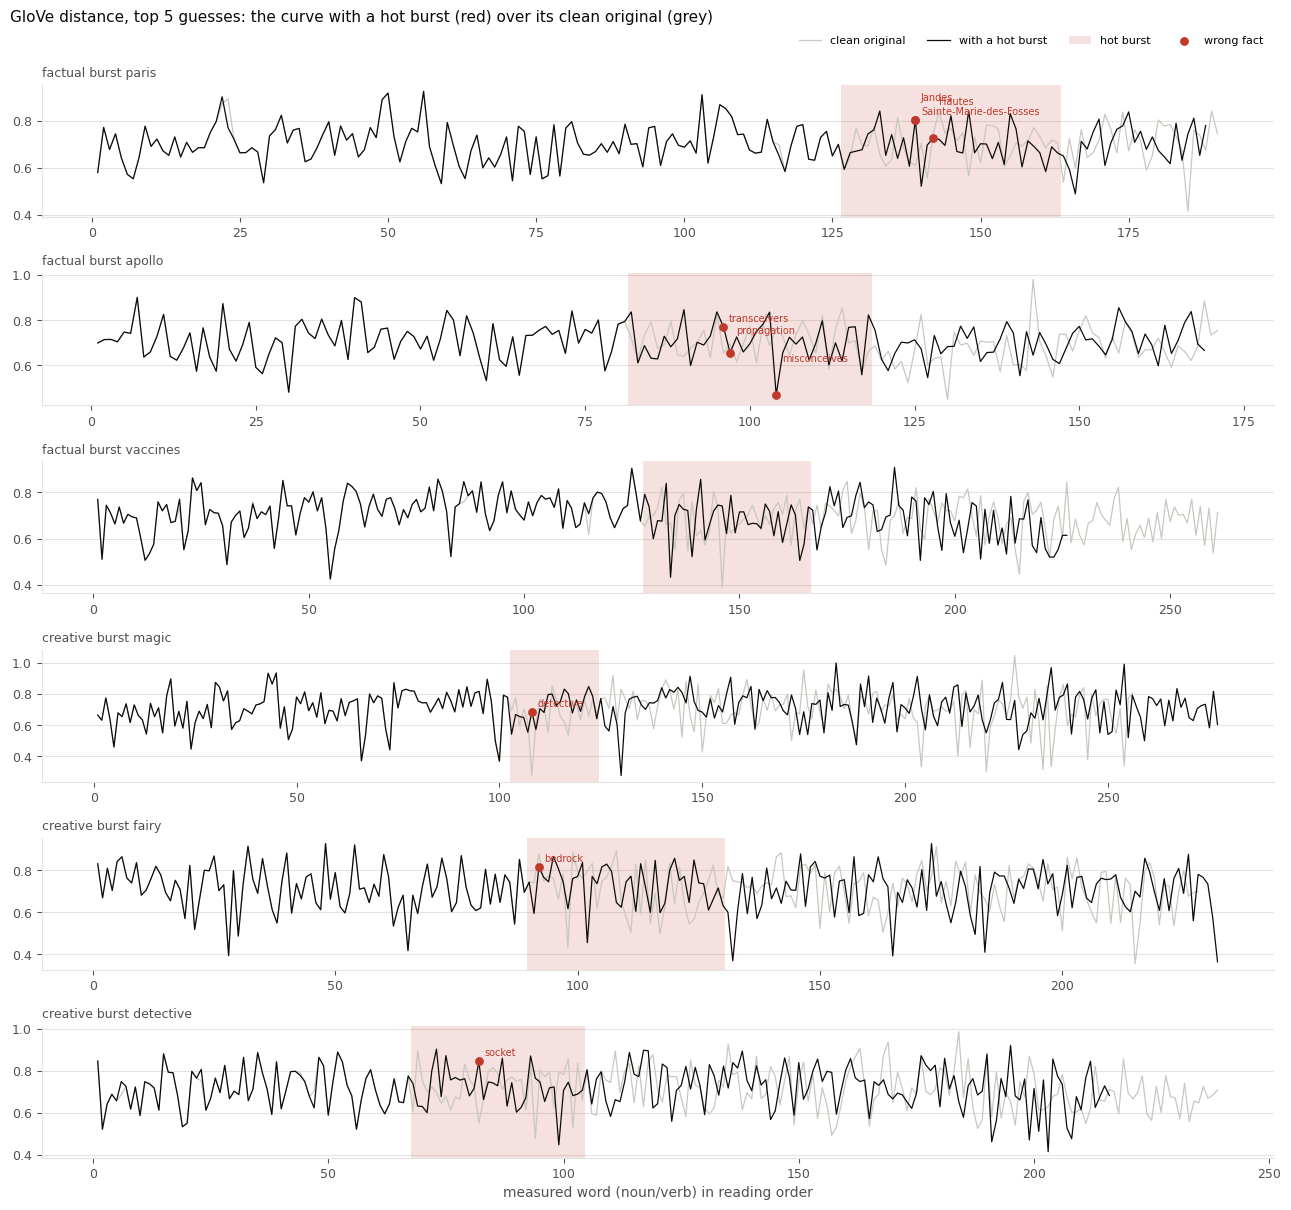

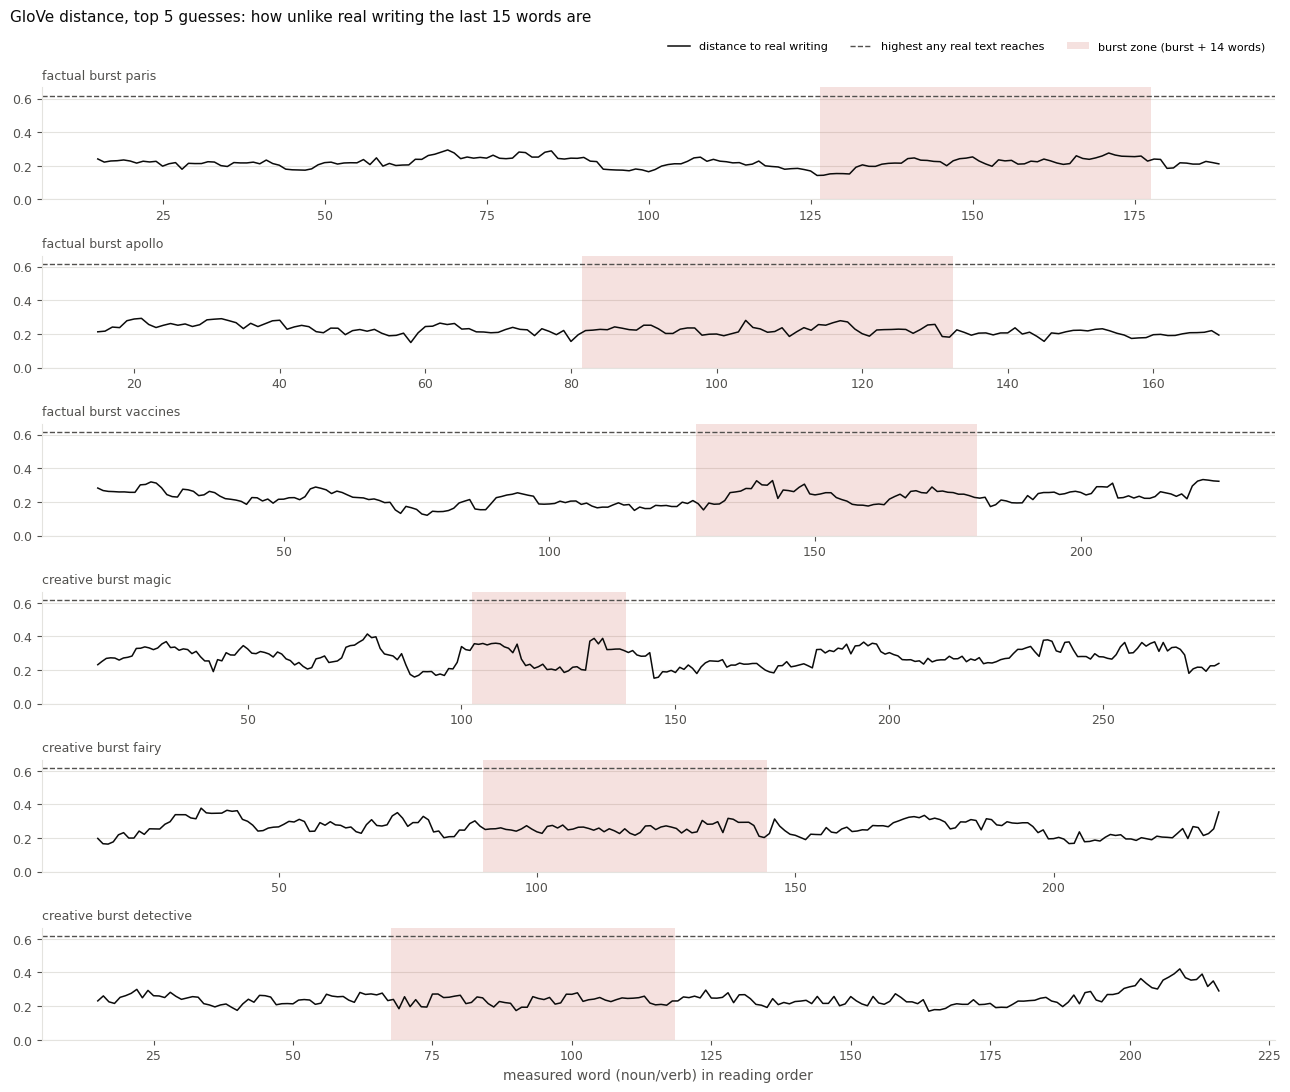

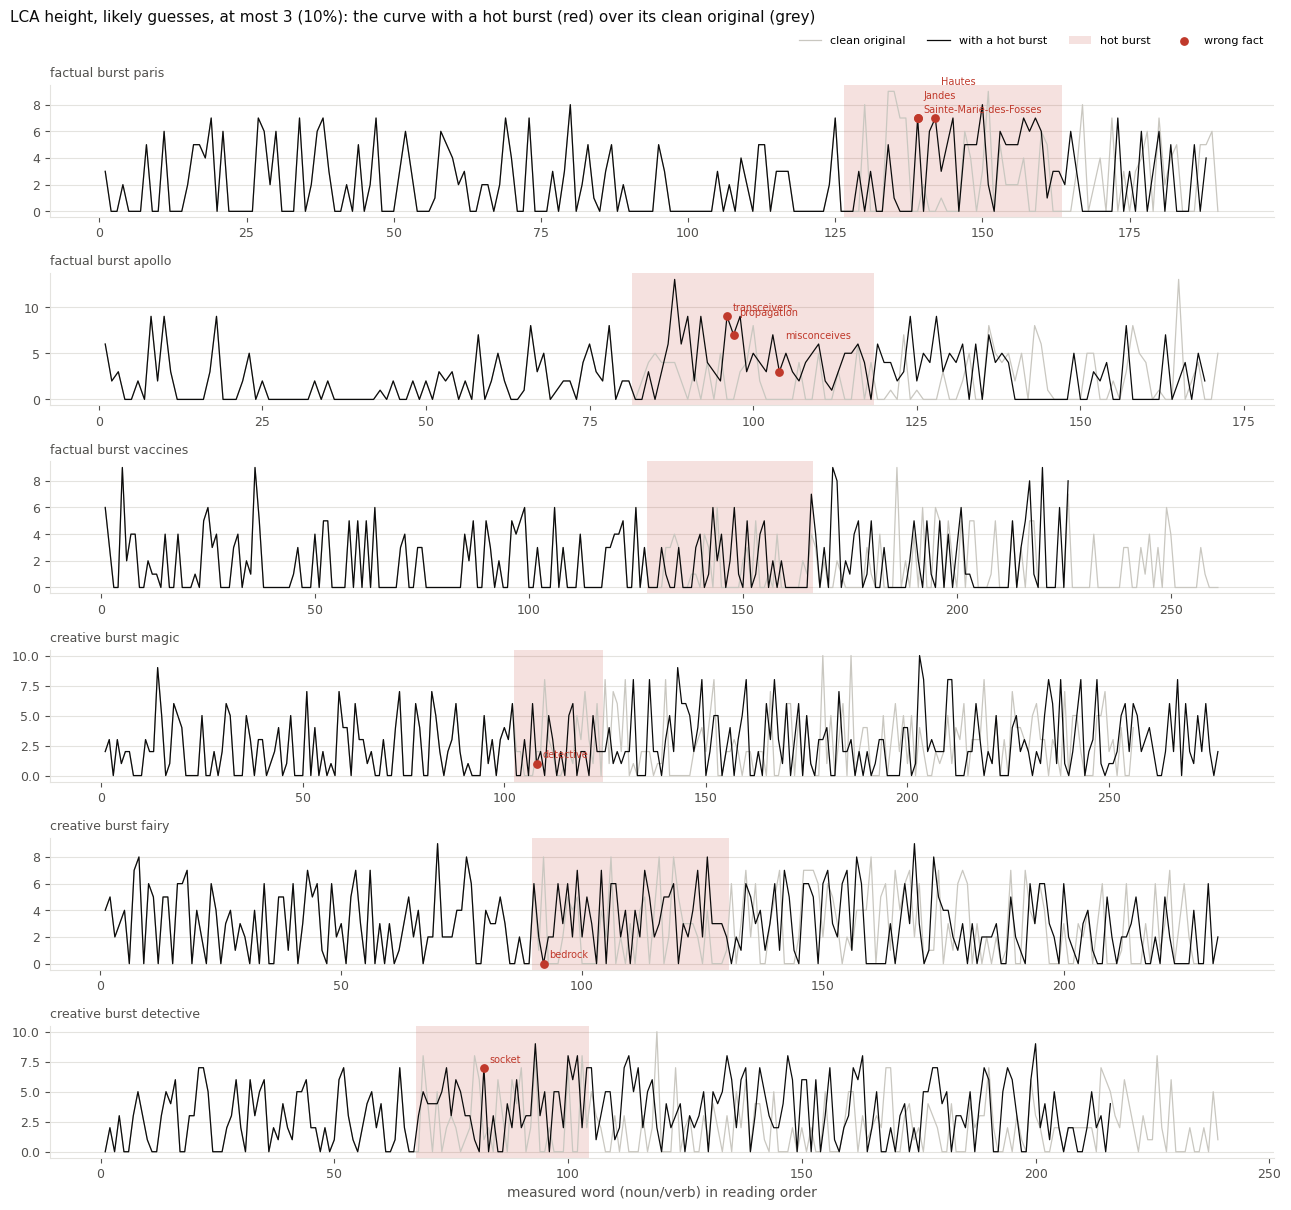

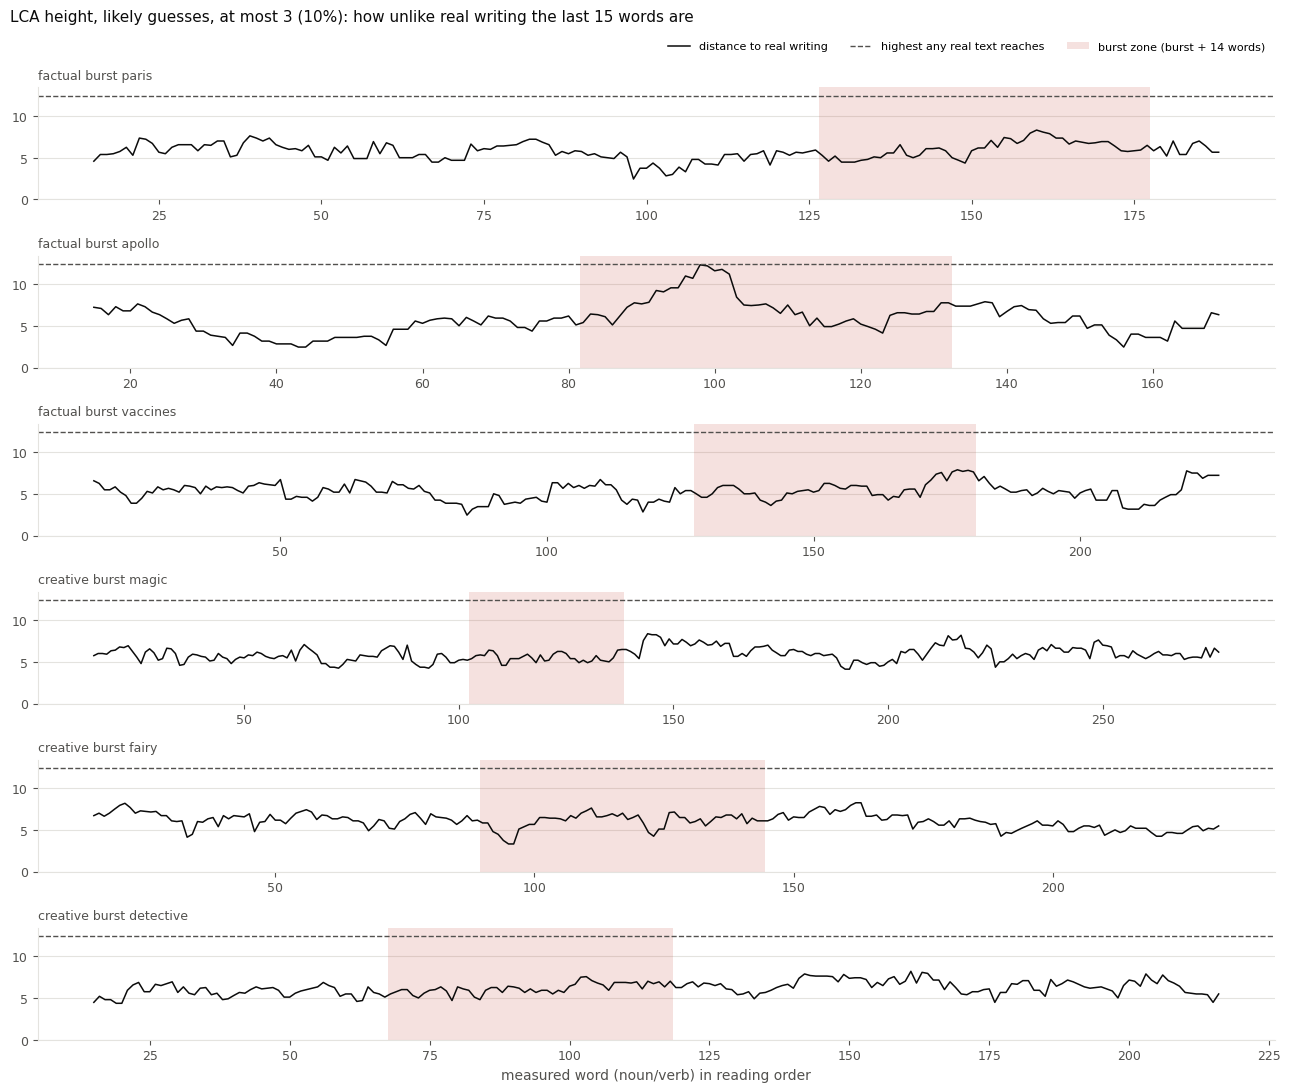

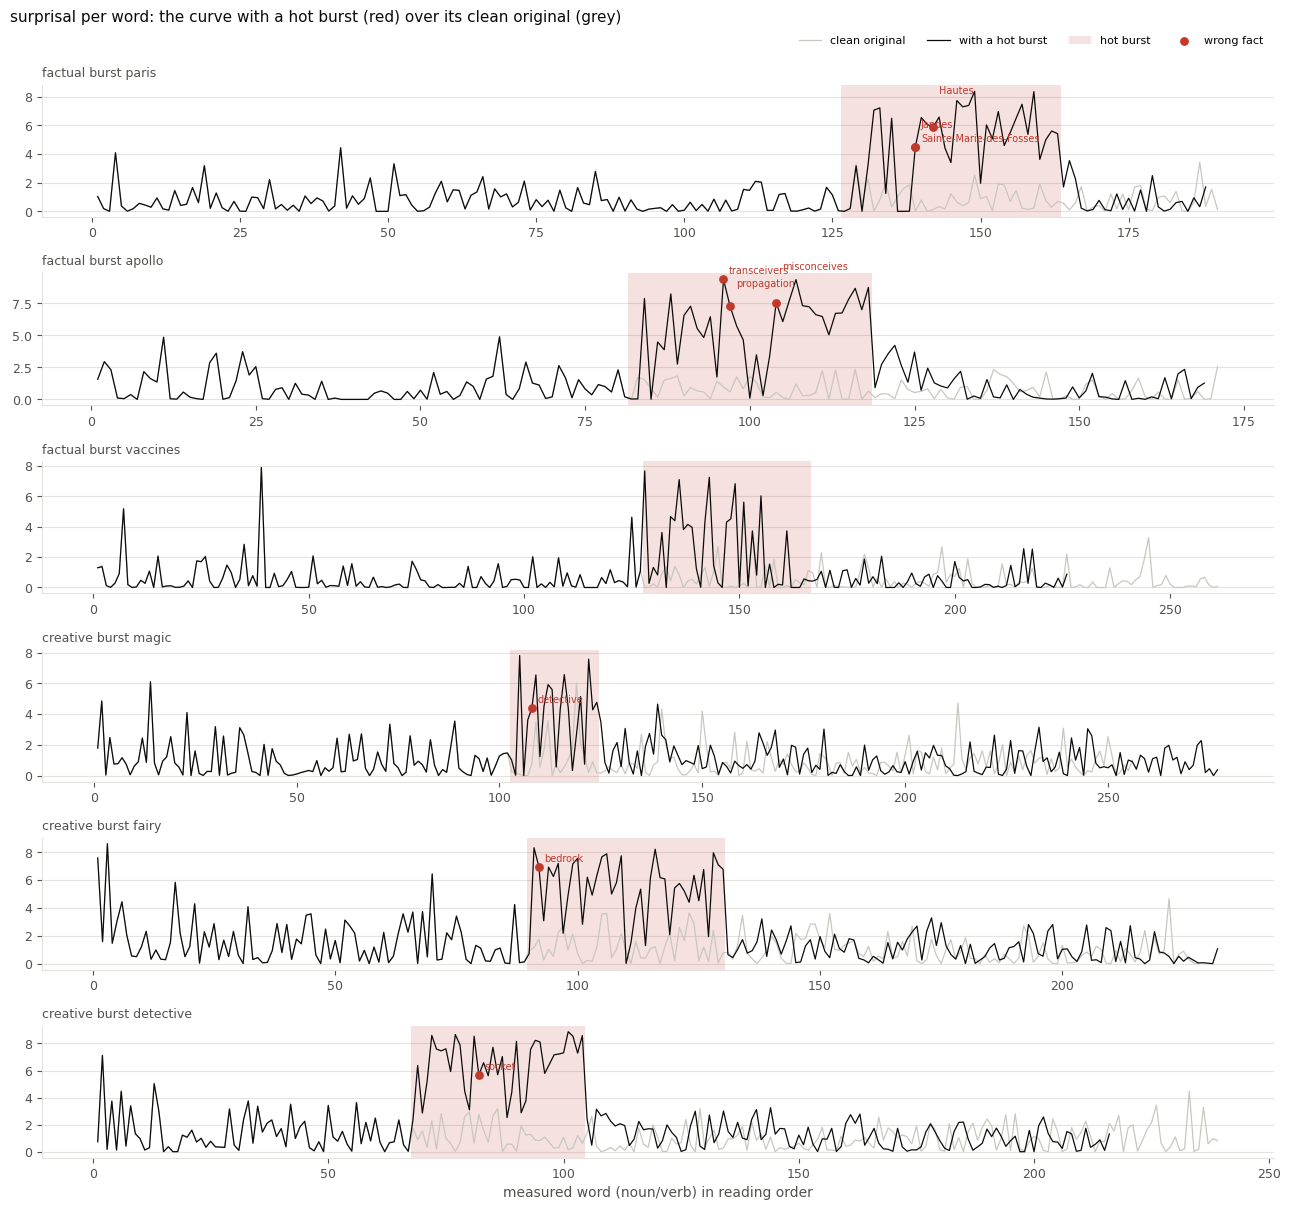

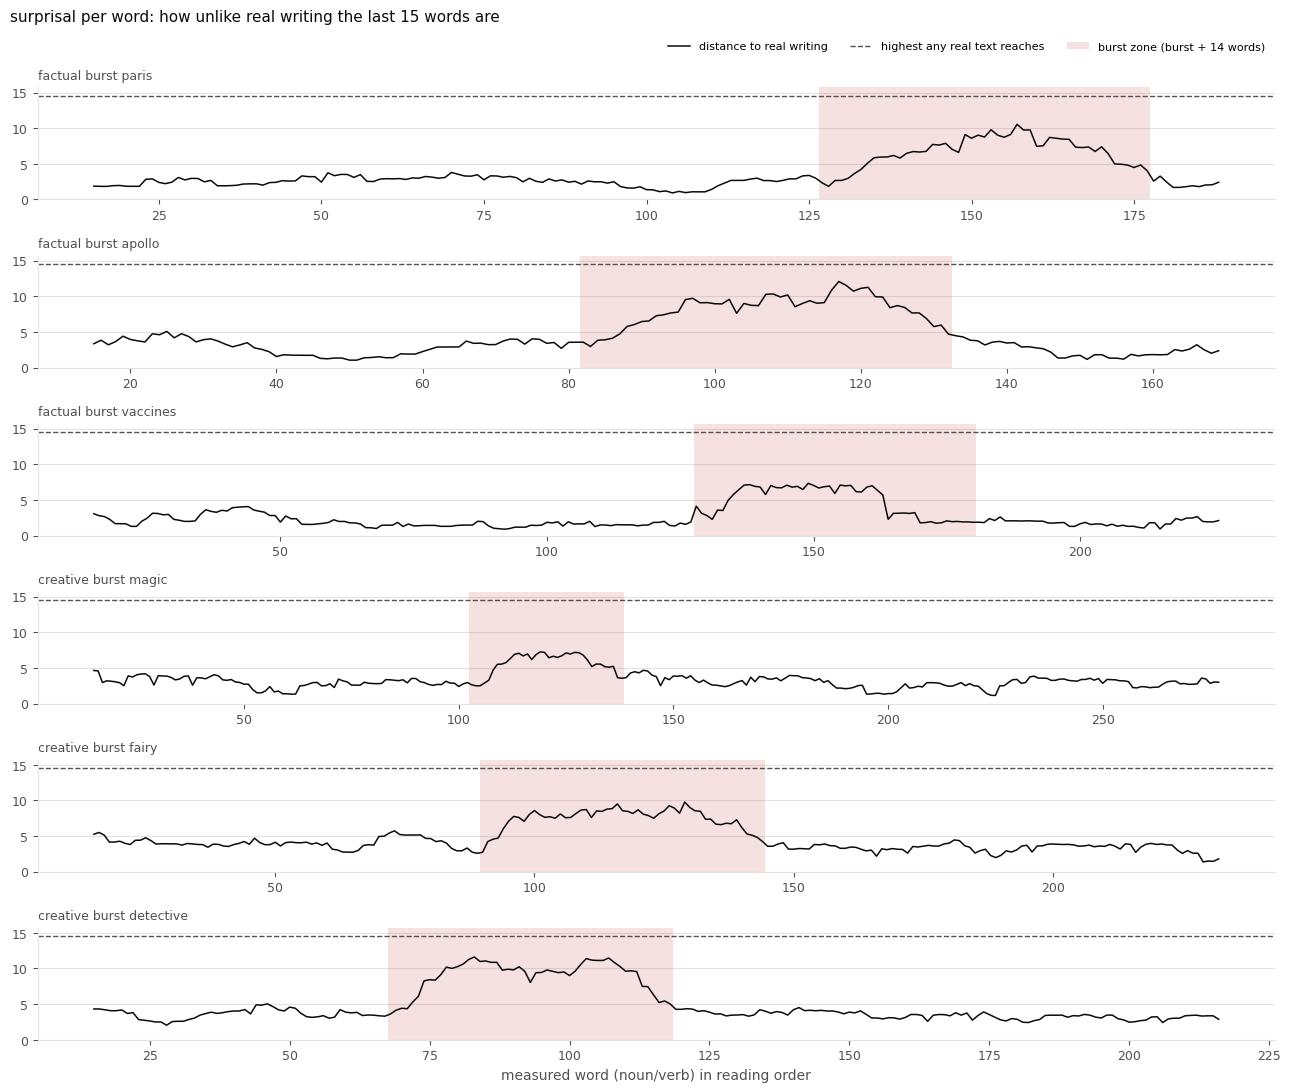

,text,signal,burst words,highest in burst zone,highest elsewhere,highest in clean original,normal ceiling,peak in burst zone,above clean original
0,factual_burst_paris,"GloVe distance, top 5 guesses",127-163,0.276,0.294,0.294,0.617,False,False
1,factual_burst_paris,"LCA height, likely guesses, at most 3 (10%)",127-163,8.307,7.616,9.110,12.410,True,False
2,factual_burst_paris,surprisal per word,127-163,10.545,3.789,3.821,14.544,True,True
3,factual_burst_apollo,"GloVe distance, top 5 guesses",82-118,0.280,0.292,0.334,0.617,False,False
4,factual_burst_apollo,"LCA height, likely guesses, at most 3 (10%)",82-118,12.288,7.874,8.307,12.410,True,True
5,factual_burst_apollo,surprisal per word,82-118,12.066,5.068,5.068,14.544,True,True
6,factual_burst_vaccines,"GloVe distance, top 5 guesses",128-166,0.327,0.333,0.320,0.617,False,True
7,factual_burst_vaccines,"LCA height, likely guesses, at most 3 (10%)",128-166,7.874,7.746,7.211,12.410,True,True
8,factual_burst_vaccines,surprisal per word,128-166,7.331,4.063,4.065,14.544,True,True
9,creative_burst_magic,"GloVe distance, top 5 guesses",103-124,0.388,0.414,0.482,0.617,False,False


In [4]:
real_names = dataset_names()
real_kinds = kinds_of(real_names)
real_words, real_tokens = load_tables(real_names, MODEL_NAME)
burst_names = list(bursts["text"])
clean_names = list(bursts["clean original"])
burst_words, burst_tokens = load_tables(burst_names, MODEL_NAME, BURST_WORDS_DIR, BURST_TOKENS_DIR)
clean_words, clean_tokens = load_tables(clean_names, MODEL_NAME, BURST_WORDS_DIR, BURST_TOKENS_DIR)
marks = pd.read_csv(BURST_DIR / "marks.csv")

references = {}
ceilings = {}
for signal_key in EVOLVING_SIGNALS:
    signal = signal_by_key(signal_key)
    real_curves = curves_of(signal, real_names, real_words, real_tokens)
    references[signal.name] = references_by_cluster(real_names, real_kinds, real_curves)
    ceilings[signal.name] = normal_ceiling(dict(zip(real_names, real_curves)), references[signal.name],
                                           EVOLVING_WINDOW)

result_rows = []
stacked = {}                 # signal name -> one entry per text for the stacked curves figure
distances = {}               # signal name -> one entry per text for the stacked distance figure
for _index, burst in bursts.iterrows():
    name, clean_name = burst["text"], burst["clean original"]
    table = burst_words[name]
    first_row = first_row_from_char(table, int(burst["burst start char"]))
    after_row = first_row_from_char(table, int(burst["burst end char"]))   # first measured word after the burst
    for signal_key in EVOLVING_SIGNALS:
        signal = signal_by_key(signal_key)
        values, rows = curve_with_rows(table, signal.column)
        clean_values, _clean_rows = curve_with_rows(clean_words[clean_name], signal.column)
        burst_profile = evolving_profile(values, references[signal.name], EVOLVING_WINDOW)
        clean_profile = evolving_profile(clean_values, references[signal.name], EVOLVING_WINDOW)

        # the burst's measured words on this curve: from the first at or after its start to the last before its end
        first = int(np.searchsorted(rows, first_row)) if first_row is not None else len(rows)
        if after_row is None:
            last = len(rows) - 1
        else:
            last = int(np.searchsorted(rows, after_row)) - 1
        # each marked wrong fact on this curve: the first measured word at or after it
        text_marks = []
        for _mark_index, mark in marks[marks["text"] == name].iterrows():
            row = first_row_from_char(table, int(mark["char"]))
            if row is not None and np.searchsorted(rows, row) < len(rows):
                text_marks.append((int(np.searchsorted(rows, row)), mark["word"]))
        stacked.setdefault(signal.name, []).append(
            {"name": name, "values": values, "clean_values": clean_values,
             "burst": (first, last) if first <= last else None, "marks": text_marks})
        distances.setdefault(signal.name, []).append(
            {"name": name, "distance": burst_profile["to nearest"].to_numpy(),
             "burst": (first, last) if first <= last else None})
        if first > last:
            continue

        distance = burst_profile["to nearest"].to_numpy()
        in_zone = np.zeros(len(distance), dtype=bool)
        in_zone[first:last + EVOLVING_WINDOW] = True
        zone_max = np.nanmax(distance[in_zone]) if np.isfinite(distance[in_zone]).any() else np.nan
        other_max = np.nanmax(distance[~in_zone]) if np.isfinite(distance[~in_zone]).any() else np.nan
        clean_max = float(np.nanmax(clean_profile["to nearest"]))
        result_rows.append({"text": name, "signal": signal.name, "burst words": f"{first + 1}-{last + 1}",
                            "highest in burst zone": round(float(zone_max), 3),
                            "highest elsewhere": round(float(other_max), 3),
                            "highest in clean original": round(clean_max, 3),
                            "normal ceiling": round(ceilings[signal.name], 3),
                            "peak in burst zone": bool(zone_max > other_max),
                            "above clean original": bool(zone_max > clean_max)})

for signal_key in EVOLVING_SIGNALS:
    signal = signal_by_key(signal_key)
    fig = plot_bursts_stacked(signal.name, stacked[signal.name])
    save_to(fig, BURST_FIGURES_DIR, f"bursts_{signal_key}.png")
    plt.show()
    fig = plot_distance_stacked(signal.name, distances[signal.name], ceilings[signal.name])
    save_to(fig, BURST_FIGURES_DIR, f"distance_{signal_key}.png")
    plt.show()

results = pd.DataFrame(result_rows)
results.to_csv(BURST_TABLES_DIR / "burst_vs_clean.csv", index=False)
results

## 4. The answer: does a hallucinating stretch show in the curve?

**What the bursts contain** (read by hand; marked words in `burst/marks.csv`):

| text | burst |
|---|---|
| paris | invented places: "Sainte-Marie-des-Fosses and Jandes", Haussmann's "Hautes Citées" |
| apollo | invented instruments ("low-gravity cross-channel propagation monitor"), then a muddle about heroes |
| vaccines | correct |
| magic, fairy, detective | one slip each: Ella called "the great detective", the king's task changes, a witness speaks "through his eye socket" |

**Surprisal finds every burst.** In all 6 texts the highest distance is in the burst zone, 1.5 to 2.8 times the
highest the clean original ever reaches (Paris 10.5 against 3.8, Apollo 12.1 against 5.1). In the figure the
distance rises as the burst starts and falls back about 15 words after it ends. It does not reach the normal ceiling
(14.5): some human texts are more surprising to Qwen than these bursts, so a fixed threshold from real writing would
miss them; the jump against the text's own earlier words is what shows.

**But surprisal finds hot writing, not wrong facts.** The correct Vaccines burst and the three story bursts rise
just as clearly as the invented Paris and Apollo facts. The burst was sampled from Qwen itself at temperature 3.0,
so its words are, by construction, ones Qwen thought unlikely; surprisal measures that, whether or not the words
are true.

**LCA reacts only to the factual bursts; GloVe to none.** On LCA, Apollo comes close to anything real writing
reaches (12.29 against 12.41), far above its clean original (8.31); Paris and Vaccines peak in their zone but no
higher than (Paris) or barely above (Vaccines) their clean originals. Around invented facts the model's guesses
scatter: the words right after the invented Paris streets and Apollo instruments are among the 3 highest LCA
values of their text. Slips inside stories do not show on LCA or GloVe.

With one burst per text this is a lead, not a result: more bursts per text (more seeds) would show whether it holds.


In [3]:
from analysis.generate import write_story_streaming
# from src.model.load_model import load_model
# from config.qwen_config import MODEL_NAME, LOAD_IN_4BIT
#
# tokenizer, model = load_model(MODEL_NAME, load_in_4bit=LOAD_IN_4BIT)
load_qwen()

prompt = "A martial artist based on son wukong who fights a green demon named piccolo"
ids = write_story_streaming(model,tokenizer,prompt,COOL_TEMPERATURE,0,kind="creative",min_p=MIN_P)


system check:
Python path: C:\Users\yoav7\miniconda3\python.exe
Torch version: 2.14.1+cu126
GPU: NVIDIA GeForce RTX 4060
PyTorch: 2.14.1+cu126
CUDA: 12.6
CUDA available: True
Capability: (8, 9)
this is include the following functions torch , torch.nn.functional as F, transformers.AutoTokenizer, transformers.AutoModelForCausalLM


W1122 22:30:10.889000 32320 site-packages\torch\utils\flop_counter.py:113] triton not found; flop counting will not work for triton kernels


Loading weights:   0%|          | 0/339 [00:00<?, ?it/s]

In the heart of a dense, misty forest, under the watchful gaze of towering pines and ancient oaks, a martial artist stood prepared for a confrontation unlike any other. This was no ordinary martial artist; he was Son Wukong, the Monkey King, a being of unparalleled strength and agility, known across the land for his feats of martial prowess and his insatiable curiosity for the unknown. Tonight, he faced a formidable opponent, a green demon named Piccolo.

Piccolo, with his emerald skin and piercing eyes, was a creature of ancient lore, feared and revered in equal measure. He had been banished from his home by a powerful deity for a transgression that Wukong could not fathom, and now, he sought to prove his worth through combat.

The forest was silent, save for the rustling leaves and the distant call of a night bird. Wukong, dressed in his customary golden armor and armed with his staff, the Ruyi Jingu Bang, stood at the edge of the clearing, his muscles coiled like a spring, ready to 